In [ ]:
!nvidia-smi

Tue Nov 10 11:49:15 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Скачиваем cat...
Скачиваем dog...
candidate_label
cat    50
dog    50


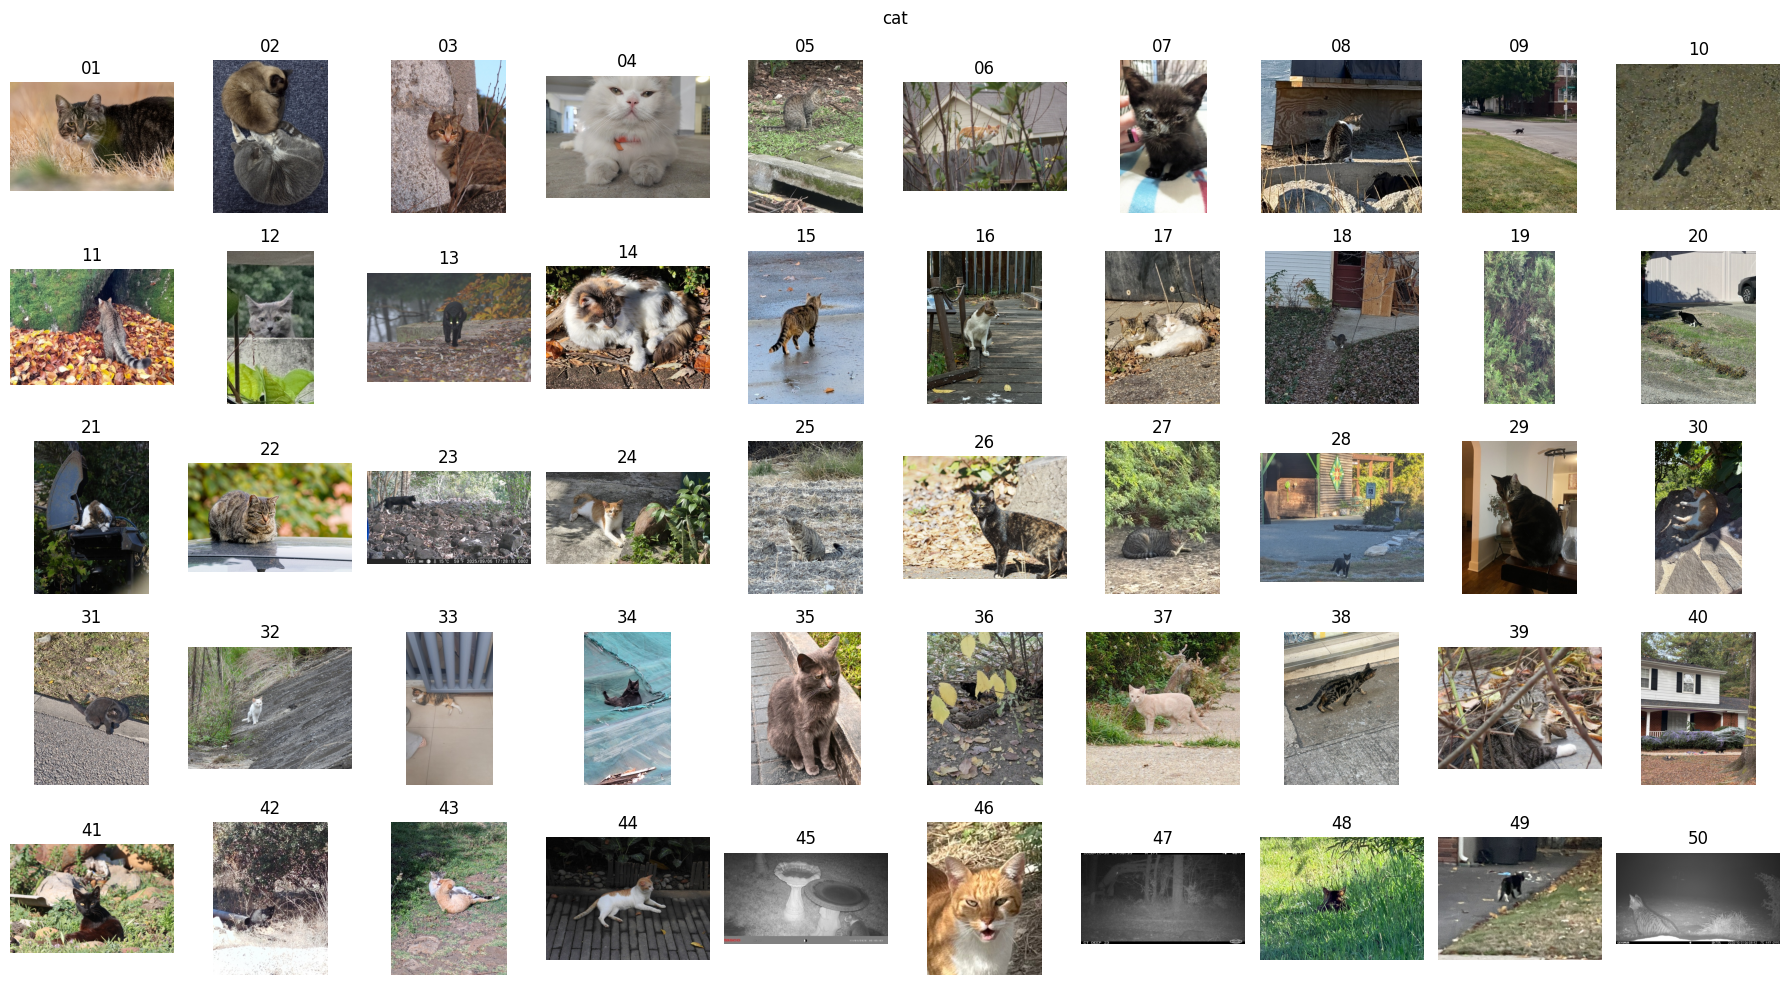

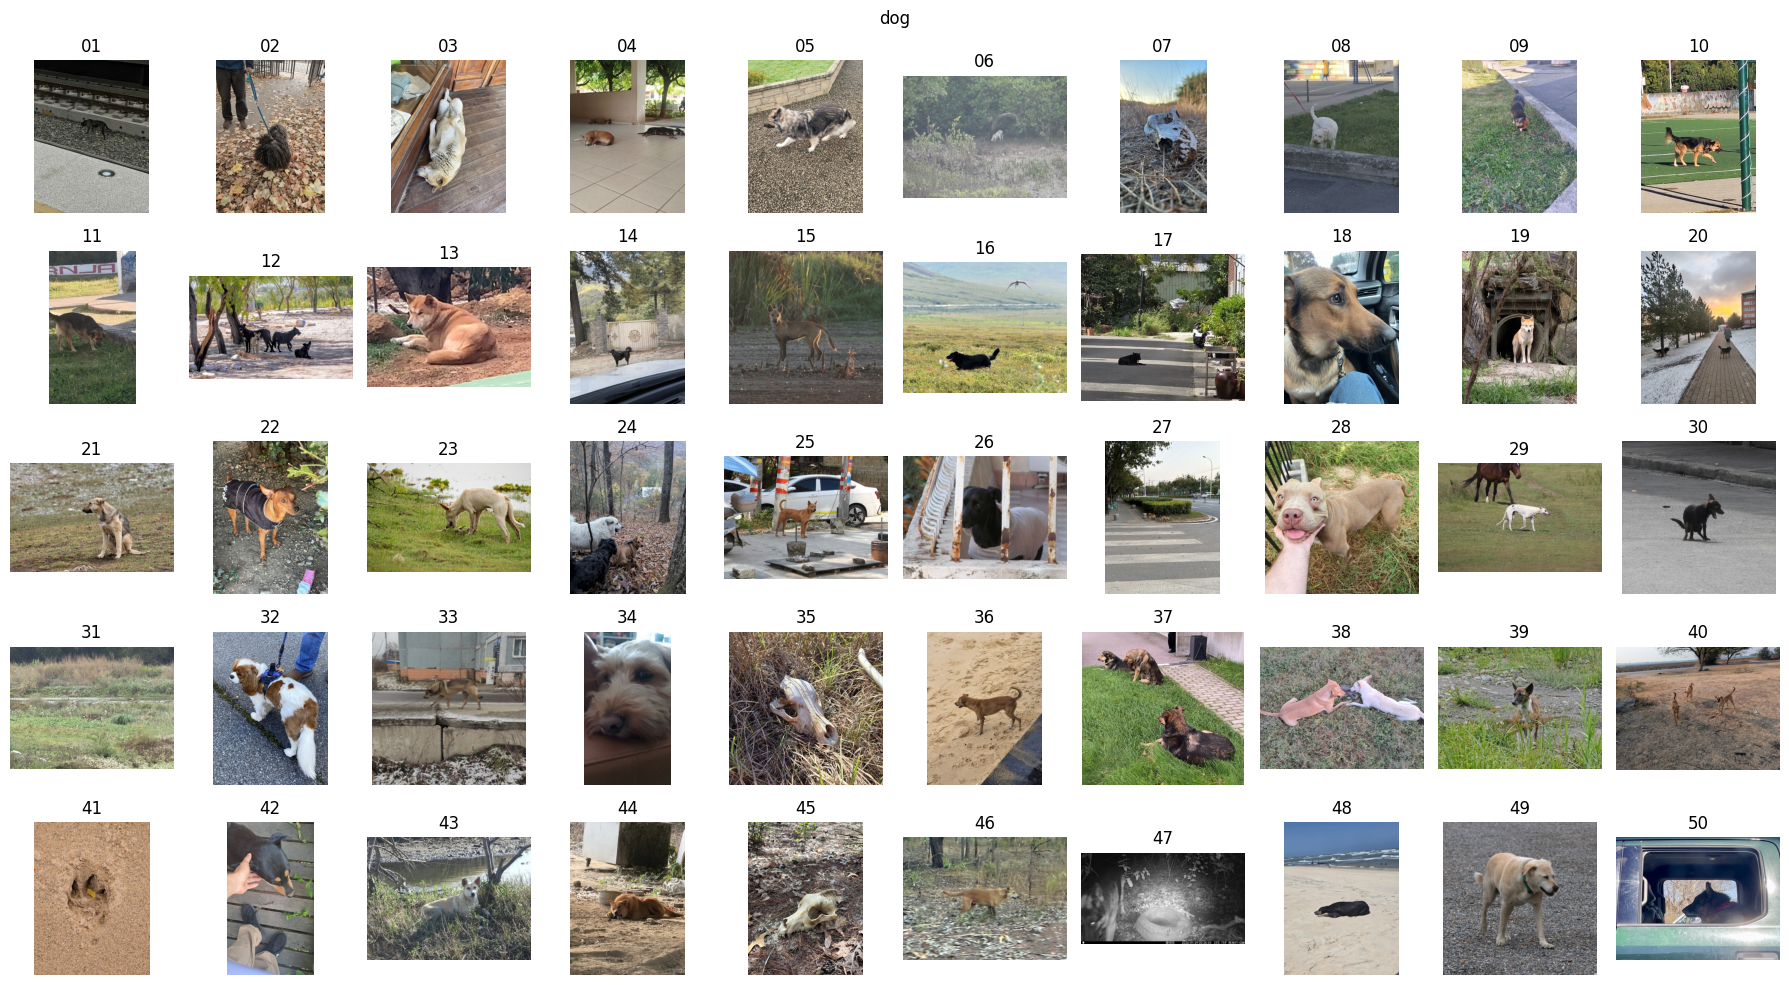

In [ ]:
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests
from PIL import Image, ImageOps

ROOT = Path("/content/lab3_test_candidates")
TAXA = {"cat": 118552, "dog": 47144}
PER_CLASS = 50
LICENSES = ("cc0", "cc-by", "cc-by-sa")
API = "https://api.inaturalist.org/v1/observations"


def collect_photos(session, label, taxon_id, used_photos):
    (ROOT / label).mkdir(parents=True, exist_ok=True)
    selected = []
    used_observers = set()
    params = {
        "taxon_id": taxon_id,
        "photos": "true",
        "d1": "2023-01-01",
        "photo_license": ",".join(LICENSES),
        "per_page": 100,
        "order_by": "id",
        "order": "desc",
    }

    for _ in range(10):
        response = session.get(API, params=params, timeout=30)
        response.raise_for_status()
        observations = response.json()["results"]
        if not observations:
            break
        params["id_below"] = observations[-1]["id"]

        for obs in observations:
            observer = obs["user"]["id"]
            if observer in used_observers:
                continue

            photo = next(
                (p for p in obs["photos"] if p.get("url")
                 and p.get("license_code") in LICENSES and p["id"] not in used_photos),
                None,
            )
            if photo is None:
                continue

            image_url = photo["url"].replace("/square.", "/medium.")
            response = session.get(image_url, timeout=25)
            if response.status_code in (403, 404):
                continue
            response.raise_for_status()
            try:
                with Image.open(BytesIO(response.content)) as source:
                    image = ImageOps.exif_transpose(source).convert("RGB")
            except OSError:
                continue

            path = Path(label) / f"{len(selected) + 1:02d}.jpg"
            image.save(ROOT / path, quality=95)
            used_observers.add(observer)
            used_photos.add(photo["id"])
            selected.append({
                "file": path.as_posix(),
                "candidate_label": label,
                "observed_on": obs["observed_on"],
                "source": f"https://www.inaturalist.org/photos/{photo['id']}",
                "attribution": photo.get("attribution", ""),
                "license": photo["license_code"],
            })

            if len(selected) == PER_CLASS:
                return selected

    raise RuntimeError(f"{label}: собрано {len(selected)} из {PER_CLASS} фото.")


rows = []
used_photos = set()
with requests.Session() as session:
    for label, taxon_id in TAXA.items():
        print(f"Скачиваем {label}...", flush=True)
        rows.extend(collect_photos(session, label, taxon_id, used_photos))

manifest = pd.DataFrame(rows)
manifest.to_csv(ROOT / "sources.csv", index=False)
print(manifest["candidate_label"].value_counts().to_string())

for label in TAXA:
    files = manifest.loc[manifest["candidate_label"] == label, "file"]
    fig, axes = plt.subplots(5, 10, figsize=(18, 10))
    fig.suptitle(label)
    for ax, file in zip(axes.flat, files):
        with Image.open(ROOT / file) as image:
            ax.imshow(image)
        ax.set_title(Path(file).stem)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

In [ ]:
from pathlib import Path

import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
from torchvision.datasets import OxfordIIITPet

data_root = Path("/content/lab3_data")
OxfordIIITPet(root=data_root, split="trainval", download=True)

pet_dir = data_root / "oxford-iiit-pet"
annotations = pet_dir / "annotations" / "trainval.txt"

class_names = {1: "cat", 2: "dog"}
records = []
unreadable = []

for line in annotations.read_text().splitlines():
    image_id, _, species_id, _ = line.split()
    image_path = pet_dir / "images" / f"{image_id}.jpg"
    species_id = int(species_id)

    try:
        with Image.open(image_path) as image:
            image.load()
    except OSError:
        unreadable.append(image_path.name)
        continue

    records.append({
        "path": str(image_path),
        "label": species_id - 1,
        "class_name": class_names[species_id],
    })

pets_df = pd.DataFrame(records)
train_df, val_df = train_test_split(
    pets_df,
    test_size=0.20,
    random_state=42,
    stratify=pets_df["label"],
)

counts = pd.DataFrame({
    "train": train_df["class_name"].value_counts(),
    "val": val_df["class_name"].value_counts(),
}).reindex(["cat", "dog"])

print(counts.to_string())
print(f"\nПропущено нечитаемых фото: {len(unreadable)}")

100%|██████████| 792M/792M [00:36<00:00, 21.9MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 8.24MB/s]


            train  val
class_name            
cat           950  238
dog          1994  498

Пропущено нечитаемых фото: 0
